# Stiffness in Confined Quantum Walks

**Based on:** P. G. M. Dantas, R. Vieira, and E. P. M. Amorim, *Stiffness in Confined Quantum Walks*

This notebook develops the paper's argument in the same order as its theoretical and numerical sections. It combines short explanations, equations, reproducible Python, and the cached numerical data used for the paper's plots.

### How to run this notebook

- Run the cells from top to bottom.
- The bundle includes a `data/` folder with the numerical cache files. These let you reproduce the full-size plots without repeating the longest simulations.
- The simulation function below is included so that you can run shorter experiments and change the lattice size or initial state.
- Full recomputation of the 500,000-step runs and the 91-point finite-size sweeps is intentionally not performed automatically. It can be computationally expensive.

**Conventions:** `N` denotes the number of physical (bulk) sites and is odd; the two additional sites at `j = ±(a+1)` are auxiliary reflecting sites, with `N = 2a + 1`.

## 1. Imports, data, and plotting style

The supplied caches are the numerical outputs used by the scripts for Figures 2–5. Figure 1 is evaluated directly from the analytical series in the paper.

In [14]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import norm, beta

# Locate the data folder. This works when the notebook is run from the
# extracted tutorial bundle directory.
CANDIDATES = [Path.cwd() / "data", Path.cwd() / "stiffness_walk_tutorial" / "data"]
DATA_DIR = next((p for p in CANDIDATES if p.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find the data/ folder. Extract the tutorial bundle and "
        "open this notebook from the extracted Stiffness_in_Confined_Quantum_Walks_Tutorial folder."
    )

plt.rcParams.update(
    {
        "font.family": "serif",
        "mathtext.fontset": "stix",
        "font.size": 11,
        "axes.linewidth": 1.0,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "figure.dpi": 110,
    }
)

COLORS = {"localized": "black", "gaussian": "red", "uniform": "blue"}
LABELS = ["Localized", r"Gaussian ($\sigma_0=3$)", "Truncated uniform"]

qw_data = np.load(DATA_DIR / "qw_simulation_cache.npz")
fig3_data = np.load(DATA_DIR / "fig3_cache.npz")
fig4_data = np.load(DATA_DIR / "fig4_cache.npz")
fig5_data = np.load(DATA_DIR / "fig5_cache.npz")

print("Quantum-walk cache keys:", qw_data.files)
print("Figure 3 cache keys:", fig3_data.files)
print("Figure 4 cache keys:", fig4_data.files)
print("Figure 5 cache keys:", fig5_data.files)

Quantum-walk cache keys: ['j_full', 's_loc', 'c_loc', 'snaps_loc', 't_snaps_loc', 's_gauss', 'c_gauss', 'snaps_gauss', 't_snaps_gauss', 's_unif', 'c_unif', 'snaps_unif', 't_snaps_unif']
Figure 3 cache keys: ['S_loc', 'S_gauss', 'S_unif']
Figure 4 cache keys: ['N_arr', 'S_loc_m1', 'S_loc_m2', 'S_gauss_m1', 'S_gauss_m2', 'S_unif_m1', 'S_unif_m2']
Figure 5 cache keys: ['t_max', 'tc', 'N_values', 'dkl_series', 'N_arr', 'mean_dkl', 'mean_dkl2']


In [15]:
# Basic cache checks: dimensions, time span, and probability normalization.
j = qw_data["j_full"]
assert j.size == 103 and np.isclose(j[0], -51) and np.isclose(j[-1], 51)
assert qw_data["s_loc"].shape == (500_001,)
assert fig3_data["S_loc"].shape == (500_000,)
assert fig4_data["N_arr"].size == 91
assert fig5_data["dkl_series"].shape == (3, 500_001)

for state in ["loc", "gauss", "unif"]:
    snaps = qw_data[f"snaps_{state}"]
    sums = snaps.sum(axis=1)
    print(
        f"{state:>5s} snapshot probability sums: min={sums.min():.12f}, max={sums.max():.12f}"
    )

  loc snapshot probability sums: min=0.999999999912, max=1.000000000000
gauss snapshot probability sums: min=0.999999999913, max=1.000000000000
 unif snapshot probability sums: min=0.999999999913, max=1.000000000000


## 2. Classical reference: diffusion with reflecting boundaries

The paper first considers a classical probability density on `x ∈ [-1,1]`. It obeys the diffusion equation

$$
\partial_t p(x,t)=D\,\partial_x^2p(x,t),
\tag{1}
$$

with reflecting (Neumann) boundary conditions

$$
\partial_xp(-1,t)=\partial_xp(1,t)=0.
\tag{2}
$$

For a walker initially localized at the origin, the even-mode solution is

$$
p(x,t)=\frac12+\sum_{n=1}^{\infty}\cos(n\pi x)\,e^{-D n^2\pi^2t},
\tag{3}
$$

and its variance is

$$
\sigma^2(t)=\frac13+\frac{4}{\pi^2}\sum_{n=1}^{\infty}
\frac{(-1)^n}{n^2}e^{-D n^2\pi^2t}.
\tag{4}
$$

All nonuniform modes decay. Thus `p(x,t)` approaches `1/2`, and the width approaches the standard deviation of a uniform distribution on `[-1,1]`, `1/√3`.

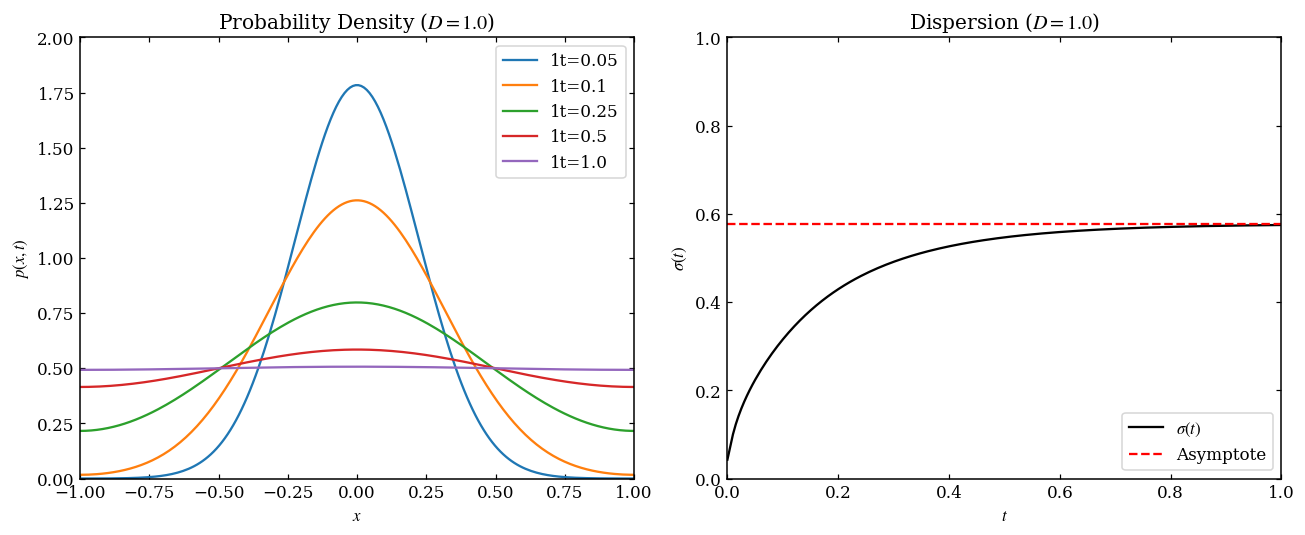

In [16]:
# 1. Math functions with diffusion coefficient D
def p(x, t, D=1.0, n_terms=10):
    result = 0.5
    for n in range(1, n_terms + 1):
        result += np.cos(n * np.pi * x) * np.exp(-D * (n**2) * np.pi**2 * t / 2)
    return result


def sigma(t, D=1.0, n_terms=10):
    sum_terms = 0
    for n in range(1, n_terms + 1):
        sum_terms += ((-1) ** n / n**2) * np.exp(-D * (n**2) * np.pi**2 * t / 2)
    variance = np.maximum(1 / 3 + (4 / np.pi**2) * sum_terms, 0)
    return np.sqrt(variance)


# 3. Generate data
x = np.linspace(-1, 1, 200)
t_array = np.linspace(0, 1, 200)
times = [0.05, 0.1, 0.25, 0.5, 1.0]

# 4. Create side-by-side subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# First Subplot: p(x,t)
for t in times:
    ax1.plot(x, p(x, t, D=1.0), label=f"1t={t}")

ax1.set(xlim=(-1, 1), ylim=(0, 2), xlabel="$x$", ylabel="$p(x,t)$")
ax1.set_title(f"Probability Density ($D = 1.0$)")
ax1.legend(loc="upper right")

# Second Subplot: sigma(t)
ax2.plot(t_array, sigma(t_array, D=1.0), color="black", label=r"$\sigma(t)$")
ax2.axhline(y=1 / np.sqrt(3), color="red", linestyle="--", label="Asymptote")

ax2.set(xlim=(0, 1), ylim=(0, 1), xlabel="$t$", ylabel=r"$\sigma(t)$")
ax2.set_title(f"Dispersion ($D = 1.0$)")
ax2.legend(loc="lower right")

# 5. Clean up spacing, save and display
plt.tight_layout()
plt.show()

## 3. The confined discrete-time quantum walk

A discrete-time quantum walker has two degrees of freedom:

- a two-dimensional **coin** space, with basis `|L⟩` and `|R⟩`;
- a **position** space, with lattice basis `|j⟩`.

The state can be written as

$$
|\Psi(t)\rangle=\sum_j\left[\psi_L(j,t)|L\rangle+\psi_R(j,t)|R\rangle\right]\otimes|j\rangle.
\tag{5}
$$

The probability at site `j` is

$$
P(j,t)=|\psi_L(j,t)|^2+|\psi_R(j,t)|^2,
\tag{6}
$$

and the spatial width is

$$
\sigma(t)=\sqrt{\langle j^2\rangle_t-\langle j\rangle_t^2}.
\tag{7}
$$

### Coin and shift operators

In the bulk, the coin is the Hadamard operator

$$
H=\frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}.
\tag{8}
$$

At the two auxiliary sites, the coin is the Pauli-X operator

$$
X=\begin{pmatrix}0&1\\1&0\end{pmatrix},
\tag{9}
$$


which exchanges the left and right components. The conditional shift moves `|L⟩` one site left and `|R⟩` one site right. The one-step evolution is `U = S C_p`.

The auxiliary sites are not absorbing walls. The X coin reverses the outgoing component, returning it to the physical bulk on the next shift. Since the coin and shift are unitary, the walk conserves total probability and remains coherent.

### 3.1 Initial states

The paper uses the symmetric coin state

$$
|\chi\rangle=\frac{|L\rangle+i|R\rangle}{\sqrt2},
\tag{10}
$$

which removes directional bias for a centered, symmetric setup. It is combined with three spatial profiles:

1. **Localized:** all position support at `j=0`.
2. **Gaussian:** `g(j) ∝ exp[-j²/(4σ₀²)]`, with `σ₀=3`, normalized in amplitude.
3. **Truncated uniform:** equal amplitude `1/√N` on all `N` bulk sites.

The Gaussian and uniform states begin delocalized over both parity sublattices; the localized state begins at a single site and alternates parity at successive steps.

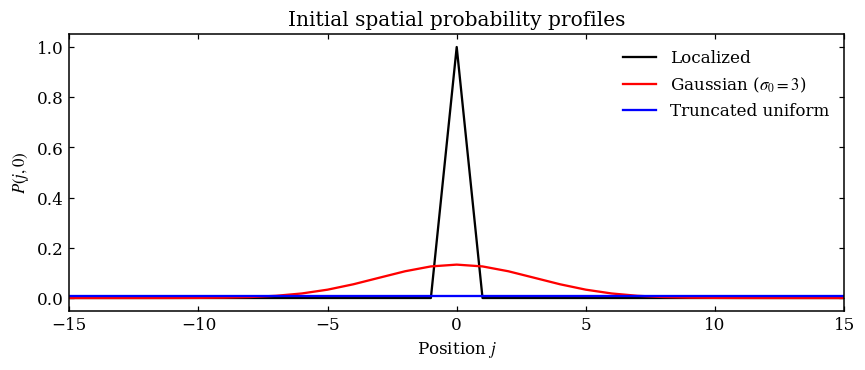

In [17]:
def make_initial_state(N=101, kind="localized", sigma0=3.0):
    """Return (j, psi_L, psi_R) for an odd number N of bulk sites.

    Two auxiliary reflector sites are included at the array endpoints.
    """
    if N < 3 or N % 2 == 0:
        raise ValueError("N must be an odd integer >= 3")
    a = (N - 1) // 2
    j = np.arange(-(a + 1), a + 2, dtype=float)  # N bulk + 2 reflector sites
    psi_L = np.zeros(N + 2, dtype=np.complex128)
    psi_R = np.zeros(N + 2, dtype=np.complex128)

    if kind == "localized":
        center = a + 1
        psi_L[center] = 1 / np.sqrt(2)
        psi_R[center] = 1j / np.sqrt(2)
    else:
        j_bulk = j[1:-1]
        if kind == "gaussian":
            envelope = np.exp(-(j_bulk**2) / (4 * sigma0**2))
            envelope = envelope / np.sqrt(np.sum(envelope**2))
        elif kind == "uniform":
            envelope = np.ones(N, dtype=float) / np.sqrt(N)
        else:
            raise ValueError("kind must be 'localized', 'gaussian', or 'uniform'")
        psi_L[1:-1] = envelope / np.sqrt(2)
        psi_R[1:-1] = 1j * envelope / np.sqrt(2)

    return j, psi_L, psi_R


def position_probability(psi_L, psi_R):
    return np.abs(psi_L) ** 2 + np.abs(psi_R) ** 2


def spatial_width(j, probability):
    mean_j = np.sum(j * probability)
    mean_j2 = np.sum((j**2) * probability)
    return np.sqrt(max(0.0, mean_j2 - mean_j**2))


def coin_coherence(psi_L, psi_R):
    # C(t) = |rho_LR(t)|^2, rho_LR = sum_j psi_L(j) psi_R(j)^*
    return np.abs(np.sum(psi_L * np.conjugate(psi_R))) ** 2


# Compare the three initial spatial probability profiles.
fig, ax = plt.subplots(figsize=(8, 3.5))
for kind, color, label in zip(
    ["localized", "gaussian", "uniform"],
    ["black", "red", "blue"],
    ["Localized", r"Gaussian ($\sigma_0=3$)", "Truncated uniform"],
):
    j0, L0, R0 = make_initial_state(101, kind)
    ax.plot(j0, position_probability(L0, R0), color=color, lw=1.5, label=label)
ax.set(
    xlabel="Position $j$",
    ylabel="$P(j,0)$",
    xlim=(-15, 15),
    title="Initial spatial probability profiles",
)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 3.2 Implement one unitary time step

The following code mirrors the update in `qw_simulation(1).py` and the Figure 3/4 simulation routines: Hadamard coin in the bulk, X coin at the auxiliary sites, then a conditional shift. It is written with NumPy array operations for readability; the original scripts use Numba for long simulations.

Probability sum at t=600: 0.9999999999998962


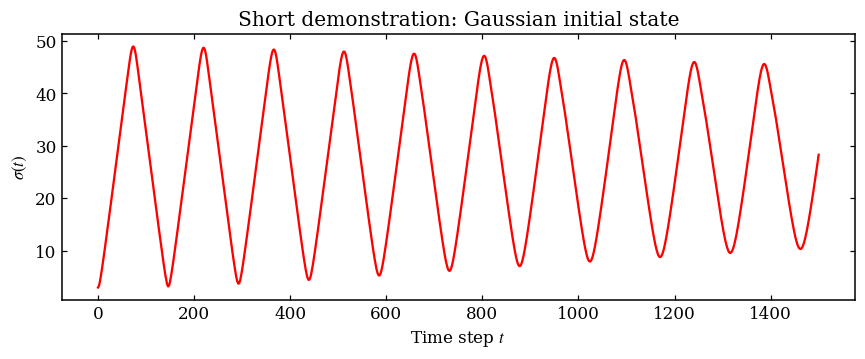

In [18]:
def quantum_walk_step(psi_L, psi_R):
    """One application of U = S C_p on the bulk plus two auxiliary sites."""
    n_sites = len(psi_L)
    c_L = np.zeros(n_sites, dtype=np.complex128)
    c_R = np.zeros(n_sites, dtype=np.complex128)
    inv_sqrt2 = 1 / np.sqrt(2)

    # Hadamard coin on the N bulk sites.
    c_L[1:-1] = (psi_L[1:-1] + psi_R[1:-1]) * inv_sqrt2
    c_R[1:-1] = (psi_L[1:-1] - psi_R[1:-1]) * inv_sqrt2

    # Pauli-X coin on the two auxiliary reflecting sites.
    c_L[0], c_R[0] = psi_R[0], psi_L[0]
    c_L[-1], c_R[-1] = psi_R[-1], psi_L[-1]

    # Conditional shift: L moves left; R moves right.
    new_L = np.zeros_like(psi_L)
    new_R = np.zeros_like(psi_R)
    new_L[:-1] = c_L[1:]
    new_R[1:] = c_R[:-1]
    return new_L, new_R


def simulate_walk(N=101, t_max=2000, kind="localized", sigma0=3.0, snapshot_times=()):
    """Moderate-size teaching simulation; returns width, coherence, and snapshots."""
    j, psi_L, psi_R = make_initial_state(N, kind, sigma0)
    sigma_t = np.empty(t_max + 1)
    coherence_t = np.empty(t_max + 1)
    snapshots = {}

    prob = position_probability(psi_L, psi_R)
    sigma_t[0] = spatial_width(j, prob)
    coherence_t[0] = coin_coherence(psi_L, psi_R)
    wanted = set(int(t) for t in snapshot_times)
    if 0 in wanted:
        snapshots[0] = prob.copy()

    for t in range(1, t_max + 1):
        psi_L, psi_R = quantum_walk_step(psi_L, psi_R)
        prob = position_probability(psi_L, psi_R)
        sigma_t[t] = spatial_width(j, prob)
        coherence_t[t] = coin_coherence(psi_L, psi_R)
        if t in wanted:
            snapshots[t] = prob.copy()

    return {"j": j, "sigma": sigma_t, "coherence": coherence_t, "snapshots": snapshots}


# A short run verifies normalization and demonstrates the oscillatory width.
small_run = simulate_walk(
    N=101, t_max=1500, kind="gaussian", snapshot_times=[0, 100, 300, 600]
)
print("Probability sum at t=600:", small_run["snapshots"][600].sum())
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(np.arange(len(small_run["sigma"])), small_run["sigma"], color="red")
ax.set(
    xlabel="Time step $t$",
    ylabel=r"$\sigma(t)$",
    title="Short demonstration: Gaussian initial state",
)
fig.tight_layout()
plt.show()

## 4. Figure 2 — confinement dynamics, width, and coin coherence

Figure 2 uses `N=101`. Its first six panels compare probability snapshots at state-dependent fractions of a characteristic time `T`. In the paper, `T` is operationally defined as the time at which the width first reaches a local minimum; it is not claimed to be an exact recurrence period. The supplied cache stores the six snapshot times for each initial condition.

Panels (g)–(i) show the width `σ(t)` in the early and long-time regimes and the empirical long-time width distribution. Panels (j)–(l) show the coin coherence

$$
C(t)=|\rho_{LR}(t)|^2=\left|\sum_j\psi_L(j,t)\psi_R(j,t)^*\right|^2,
\qquad 0\le C(t)\le\frac14.
\tag{11}
$$

The long-time histograms use `2×10⁵ < t ≤ 5×10⁵`, as in the supplied plotting script. The scaled Beta fit uses `x=4C`, so that `x∈[0,1]`.

In [19]:
# Unpack the cached Figure 2 data.
j = qw_data["j_full"]
snap_loc, snap_gauss, snap_unif = (
    qw_data[f"snaps_{s}"] for s in ["loc", "gauss", "unif"]
)
s_loc, s_gauss, s_unif = (qw_data[f"s_{s}"] for s in ["loc", "gauss", "unif"])
c_loc, c_gauss, c_unif = (qw_data[f"c_{s}"] for s in ["loc", "gauss", "unif"])

assert snap_loc.shape[0] >= 6 and snap_gauss.shape[0] >= 6 and snap_unif.shape[0] >= 6
assert len(s_loc) == len(s_gauss) == len(s_unif) == 500_001
assert len(c_loc) == len(c_gauss) == len(c_unif) == 500_001

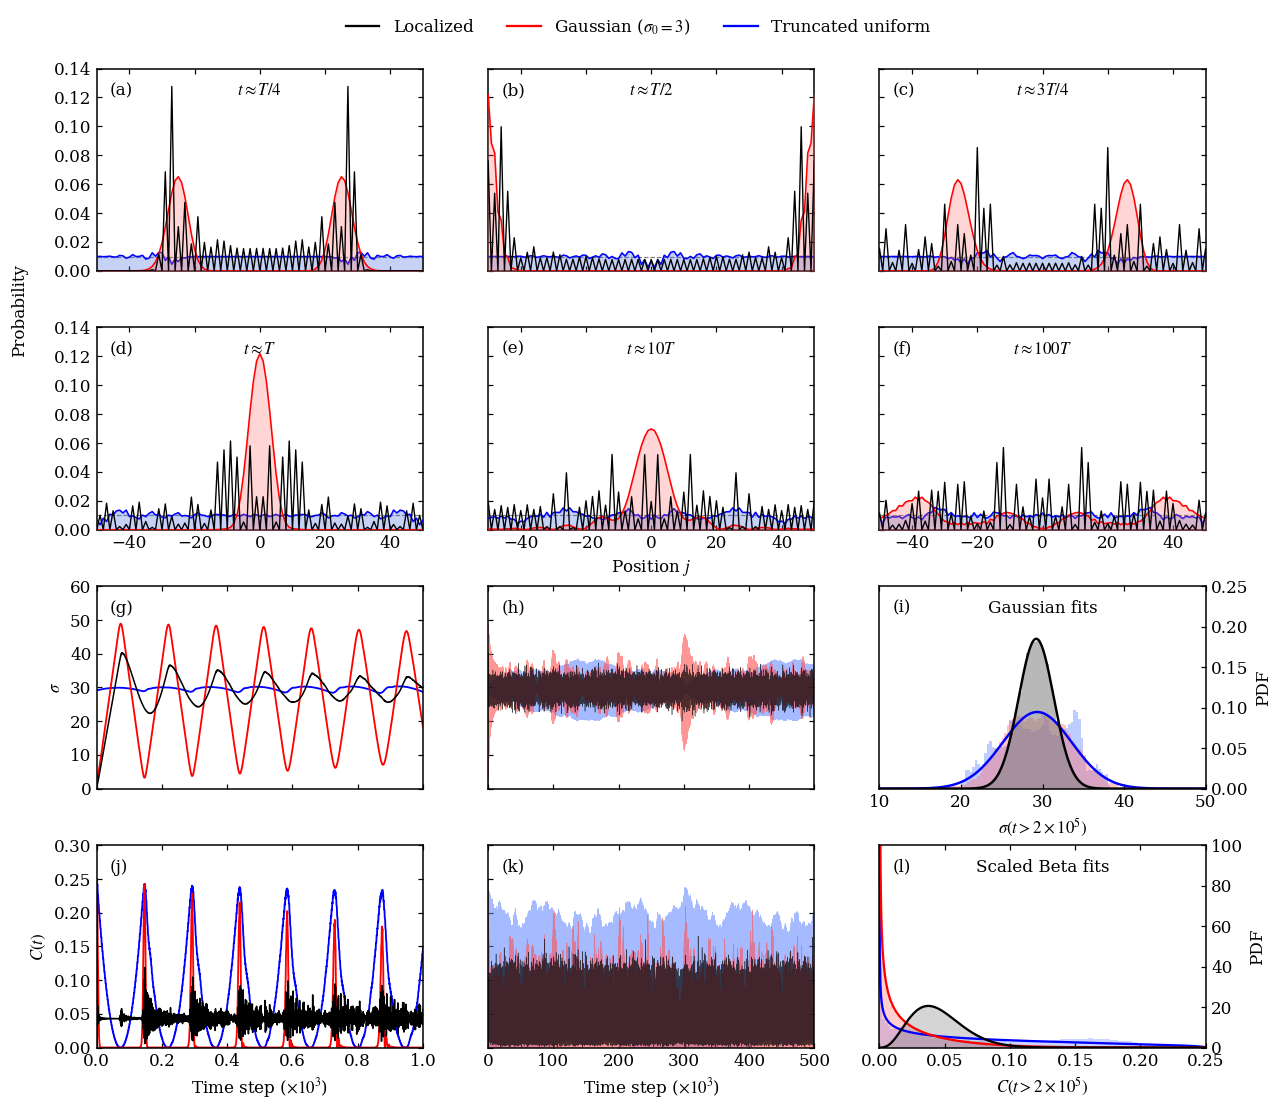

In [20]:
fig, axes = plt.subplots(4, 3, figsize=(12, 10))
col_loc, col_gauss, col_unif = "black", "red", "blue"

# Panels (a)-(f): probability distributions at state-dependent T fractions.
snap_configs = [
    (0, 0, 0, "(a)", r"$t\approx T/4$"),
    (0, 1, 1, "(b)", r"$t\approx T/2$"),
    (0, 2, 2, "(c)", r"$t\approx 3T/4$"),
    (1, 0, 3, "(d)", r"$t\approx T$"),
    (1, 1, 4, "(e)", r"$t\approx 10T$"),
    (1, 2, 5, "(f)", r"$t\approx 100T$"),
]
for row, col, idx, panel, tlabel in snap_configs:
    ax = axes[row, col]
    ax.axhline(1 / 101, color="gray", ls="--", lw=0.8, zorder=1)
    ax.fill_between(j, 0, snap_unif[idx], color="#4169e1", alpha=0.30, zorder=2)
    ax.plot(j, snap_unif[idx], color=col_unif, lw=1.0, zorder=3)
    ax.fill_between(j, 0, snap_gauss[idx], color="#ff6b6b", alpha=0.28, zorder=4)
    ax.plot(j, snap_gauss[idx], color=col_gauss, lw=1.0, zorder=5)
    ax.plot(j, snap_loc[idx], color=col_loc, lw=0.9, zorder=6)
    ax.text(0.04, 0.87, panel, transform=ax.transAxes)
    ax.text(0.50, 0.87, tlabel, transform=ax.transAxes, ha="center")
    ax.set(xlim=(-50, 50), ylim=(0, 0.14), xticks=[-40, -20, 0, 20, 40])
    ax.set_yticks(np.arange(0, 0.15, 0.02))
    if col != 0:
        ax.set_yticklabels([])
    if row == 0:
        ax.set_xticklabels([])
axes[1, 1].set_xlabel("Position $j$")
fig.text(0.025, 0.73, "Probability", rotation="vertical", va="center")

# Panels (g)-(i): width time series and its long-time empirical PDF.
t_early = np.arange(1001) / 1000
ax = axes[2, 0]
ax.plot(t_early, s_unif[:1001], color=col_unif, lw=1.2)
ax.plot(t_early, s_gauss[:1001], color=col_gauss, lw=1.2)
ax.plot(t_early, s_loc[:1001], color=col_loc, lw=1.0)
ax.text(0.04, 0.87, "(g)", transform=ax.transAxes)
ax.set(xlim=(0, 1), ylim=(0, 60), ylabel=r"$\sigma$", xticks=np.arange(0, 1.01, 0.2))
ax.set_xticklabels([])

ax = axes[2, 1]
t_long = np.arange(500001) / 1000
ax.plot(t_long, s_unif, color="#5c82ff", alpha=0.55, lw=0.35)
ax.plot(t_long, s_gauss, color="#ff5050", alpha=0.60, lw=0.35)
ax.plot(t_long, s_loc, color="black", alpha=0.70, lw=0.35)
ax.text(0.04, 0.87, "(h)", transform=ax.transAxes)
ax.set(
    xlim=(0, 500),
    ylim=(0, 60),
    xticks=np.arange(0, 501, 100),
    yticks=np.arange(0, 61, 10),
)
ax.set_xticklabels([])
ax.set_yticklabels([])

idx_tail = np.arange(200_001, 500_001)
s_loc_tail, s_gauss_tail, s_unif_tail = (
    s_loc[idx_tail],
    s_gauss[idx_tail],
    s_unif[idx_tail],
)
mu_loc, std_loc = norm.fit(s_loc_tail)
mu_unif, std_unif = norm.fit(s_unif_tail)
x_grid_s = np.linspace(10, 50, 500)
bins_s = np.linspace(15, 45, 100)
ax = axes[2, 2]
ax.hist(s_unif_tail, bins=bins_s, density=True, color="#5c82ff", alpha=0.40)
ax.hist(s_gauss_tail, bins=bins_s, density=True, color="#ff6b6b", alpha=0.40)
ax.plot(x_grid_s, norm.pdf(x_grid_s, mu_unif, std_unif), color=col_unif, lw=1.6)
ax.hist(s_loc_tail, bins=bins_s, density=True, color="#7f7f7f", alpha=0.55)
ax.plot(x_grid_s, norm.pdf(x_grid_s, mu_loc, std_loc), color=col_loc, lw=1.6)
ax.text(0.04, 0.87, "(i)", transform=ax.transAxes)
ax.text(0.50, 0.87, "Gaussian fits", transform=ax.transAxes, ha="center")
ax.set(xlim=(10, 50), ylim=(0, 0.25), xlabel=r"$\sigma(t>2\times10^5)$", ylabel="PDF")
ax.yaxis.tick_right()
ax.yaxis.set_label_position("right")

# Panels (j)-(l): coherence time series and scaled-Beta distributions.
ax = axes[3, 0]
ax.plot(t_early, c_unif[:1001], color=col_unif, lw=1.2)
ax.plot(t_early, c_gauss[:1001], color=col_gauss, lw=1.2)
ax.plot(t_early, c_loc[:1001], color=col_loc, lw=1.0)
ax.text(0.04, 0.87, "(j)", transform=ax.transAxes)
ax.set(
    xlim=(0, 1),
    ylim=(0, 0.30),
    xlabel="Time step ($\\times 10^3$)",
    ylabel="$C(t)$",
    xticks=np.arange(0, 1.01, 0.2),
)

ax = axes[3, 1]
ax.plot(t_long, c_unif, color="#5c82ff", alpha=0.55, lw=0.35)
ax.plot(t_long, c_gauss, color="#ff5050", alpha=0.60, lw=0.35)
ax.plot(t_long, c_loc, color="black", alpha=0.70, lw=0.35)
ax.text(0.04, 0.87, "(k)", transform=ax.transAxes)
ax.set(xlim=(0, 500), ylim=(0, 0.30), xticks=np.arange(0, 501, 100))
ax.set_xlabel("Time step ($\\times 10^3$)")
ax.set_yticklabels([])

c_loc_tail, c_gauss_tail, c_unif_tail = (
    c_loc[idx_tail],
    c_gauss[idx_tail],
    c_unif[idx_tail],
)
eps = 1e-10
fit_params = []
for arr in [c_loc_tail, c_gauss_tail, c_unif_tail]:
    z = np.clip(4.0 * arr, eps, 1 - eps)
    a_fit, b_fit, _, _ = beta.fit(z, floc=0, fscale=1)
    fit_params.append((a_fit, b_fit))
c_grid = np.linspace(1e-5, 0.2499, 1000)
bins_c = np.linspace(0, 0.25, 120)
ax = axes[3, 2]
for arr, (a_fit, b_fit), color, fill in [
    (c_unif_tail, fit_params[2], col_unif, "#5c82ff"),
    (c_gauss_tail, fit_params[1], col_gauss, "#ff6b6b"),
    (c_loc_tail, fit_params[0], col_loc, "#7f7f7f"),
]:
    ax.hist(arr, bins=bins_c, density=True, color=fill, alpha=0.32)
    ax.plot(c_grid, 4 * beta.pdf(4 * c_grid, a_fit, b_fit), color=color, lw=1.5)
ax.text(0.04, 0.87, "(l)", transform=ax.transAxes)
ax.text(0.50, 0.87, "Scaled Beta fits", transform=ax.transAxes, ha="center")
ax.set(xlim=(0, 0.25), ylim=(0, 100), xlabel=r"$C(t>2\times10^5)$", ylabel="PDF")
ax.yaxis.tick_right()
ax.yaxis.set_label_position("right")

handles = [
    Line2D([0], [0], color=c, lw=1.5, label=l)
    for c, l in zip([col_loc, col_gauss, col_unif], LABELS)
]
fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    frameon=False,
)
fig.subplots_adjust(
    left=0.09, right=0.93, top=0.95, bottom=0.06, wspace=0.20, hspace=0.28
)
plt.show()

### About Figure 2

- The localized and Gaussian states show pronounced early expansion and contraction as the ballistic components reach the reflectors and interfere.
- The truncated-uniform state already occupies the full bulk at `t=0`; its width starts large and its early width oscillations are much smaller.
- At long times the instantaneous probability profile continues to change. The walk does **not** relax to a static classical-like distribution.
- Long-time sampling gives similar coarse-grained width distributions for the Gaussian and truncated-uniform cases, despite their very different initial profiles. This does not mean their full instantaneous probability distributions are identical.
- The coherence lies in `[0,1/4]`. The scaled Beta curves are phenomenological fits to its empirical distribution, not a proof of a universal law.

For the symmetric initial coin, the population imbalance remains zero. The reduced coin eigenvalues therefore depend only on `C(t)`, `λ± = 1/2 ± √C(t)`, and the coin–position entanglement entropy follows from the binary von Neumann entropy of these eigenvalues.

## 5. Spreading stiffness

The paper defines the magnitude of the one-step width variation as

$$
\nu_\sigma(t)=|\sigma(t)-\sigma(t-1)|.
\tag{12}
$$

It is normalized against the asymptotic spreading rate `ν_H` of the corresponding **unconfined** Hadamard walk:

$$
S_\nu(t)=\frac{\nu_H}{\nu_H+\nu_\sigma(t)}.
\tag{13}
$$

This operational stiffness satisfies `0 < Sν ≤ 1`:

- `Sν = 1/2`: the width changes at the free-walk reference rate;
- `Sν > 1/2`: width variations are smaller than that reference;
- `Sν < 1/2`: width variations are larger than that reference;
- `Sν → 1`: the instantaneous width variation is strongly suppressed.

For the initial conditions used here, the free-walk references are `ν_H=√(1−1/√2)≈0.5412` (localized), `ν_H=0.7028` (Gaussian with `σ₀=3`), and `ν_H(N)=√I_N` (truncated uniform), where

$$
I_N=1-\frac{1}{\sqrt2}-\sqrt2\sum_{n=1}^{(N-1)/2}
(2\sqrt2-3)^n\left(1-\frac{2n}{N}\right).
\tag{14}
$$

The uniform-state reference depends on `N` because its initial support is the entire bulk and therefore changes with the confinement size.

In [21]:
def free_hadamard_rates(N=101):
    """Paper's asymptotic free-walk references for the three initial profiles."""
    nu_localized = np.sqrt(1 - 1 / np.sqrt(2))
    nu_gaussian = 0.7028
    n = np.arange(1, (N - 1) // 2 + 1)
    r = 2 * np.sqrt(2) - 3
    I_N = 1 - 1 / np.sqrt(2) - np.sqrt(2) * np.sum(r**n * (1 - 2 * n / N))
    nu_uniform = np.sqrt(I_N)
    return nu_localized, nu_gaussian, nu_uniform


print("Free Hadamard rates for N=101:", free_hadamard_rates(101))
print("Free Hadamard rates for N=1001:", free_hadamard_rates(1001))

Free Hadamard rates for N=101: (np.float64(0.541196100146197), 0.7028, np.float64(0.7046271860922374))
Free Hadamard rates for N=1001: (np.float64(0.541196100146197), 0.7028, np.float64(0.7068569868152942))


## 6. Figure 3 — stiffness over time

Figure 3 plots `Sν(t)` for `N=1001`. The dashed line at `t_c=2×10⁴` marks the end of the transient discarded in the long-time stiffness averages. The inset resolves the early dynamics.

The localized and Gaussian states begin close to the free-walk reference (`Sν≈1/2`) before boundary reflections become important. The truncated-uniform state starts near one because its initial support already spans the bulk. Repeated reflections then generate persistent, bounded oscillations.

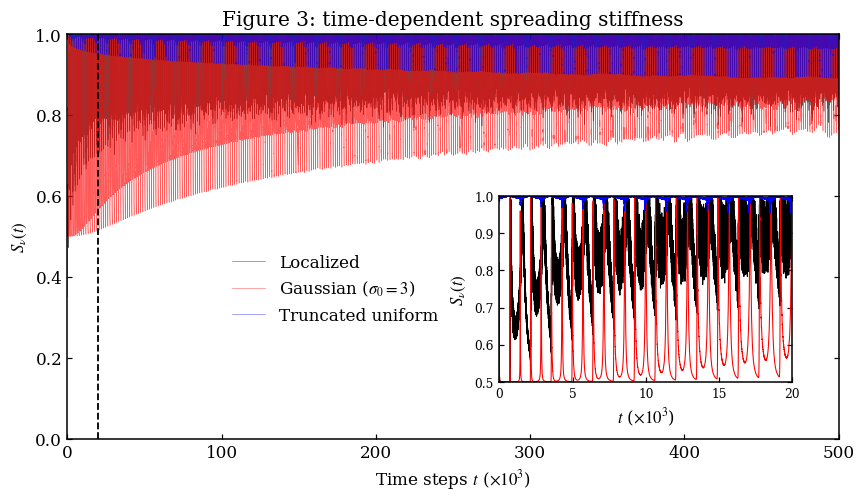

Post-transient mean stiffness (N=1001 cache):
Localized               : 0.944509
Gaussian ($\sigma_0=3$) : 0.832378
Truncated uniform       : 0.983271


In [22]:
S_loc = fig3_data["S_loc"]
S_gauss = fig3_data["S_gauss"]
S_unif = fig3_data["S_unif"]
tc_stiffness = 20_000

t = np.arange(1, len(S_loc) + 1)
fig, ax = plt.subplots(figsize=(8, 4.7))
ax.plot(t / 1000, S_loc, color="black", lw=0.35, alpha=0.65, label="Localized")
ax.plot(
    t / 1000,
    S_gauss,
    color="red",
    lw=0.35,
    alpha=0.65,
    label=r"Gaussian ($\sigma_0=3$)",
)
ax.plot(t / 1000, S_unif, color="blue", lw=0.35, alpha=0.65, label="Truncated uniform")
ax.axvline(tc_stiffness / 1000, color="black", ls="--", lw=1.2)
ax.set(
    xlim=(0, 500),
    ylim=(0, 1),
    xlabel=r"Time steps $t$ ($\times 10^3$)",
    ylabel=r"$S_\nu(t)$",
    title="Figure 3: time-dependent spreading stiffness",
)
ax.legend(frameon=False, loc="center right", bbox_to_anchor=(0.50, 0.37))
ins = ax.inset_axes([0.56, 0.14, 0.38, 0.46])
t_ins = np.arange(1, tc_stiffness + 1) / 1000
ins.plot(t_ins, S_loc[:tc_stiffness], color="black", lw=0.7)
ins.plot(t_ins, S_gauss[:tc_stiffness], color="red", lw=0.7)
ins.plot(t_ins, S_unif[:tc_stiffness], color="blue", lw=0.7)
ins.set(xlim=(0, 20), ylim=(0.5, 1), xlabel=r"$t$ ($\times10^3$)", ylabel=r"$S_\nu(t)$")
ins.tick_params(labelsize=8)
fig.tight_layout()
plt.show()

print("Post-transient mean stiffness (N=1001 cache):")
for label, arr in zip(LABELS, [S_loc, S_gauss, S_unif]):
    print(f"{label:24s}: {arr[tc_stiffness:].mean():.6f}")

## 7. Figure 4 — finite-size stiffness and moment consistency

For each confinement size and initial condition, the paper discards the first `t_c=2×10⁴` steps and averages over the remaining `T_av=4.8×10⁵` steps:

$$
\langle S_\nu^m\rangle=\frac{1}{T_{av}}
\sum_{t=t_c+1}^{t_c+T_{av}}S_\nu^m(t),\qquad m=1,2.
\tag{15}
$$

Figure 4 uses the cached first and second moments over 91 lattice sizes from `N=101` to `N=1001`.

A useful exact identity follows by defining `δ(t)=1−Sν(t)`:

$$
1-\langle S_\nu^2\rangle
=2\left(1-\langle S_\nu\rangle\right)
-\langle(1-S_\nu)^2\rangle.
\tag{16}
$$

When stiffness is high, the final term is small compared with the first deficit, yielding

$$
1-\langle S_\nu\rangle\simeq\frac12\left[1-\langle S_\nu^2\rangle\right].
\tag{17}
$$

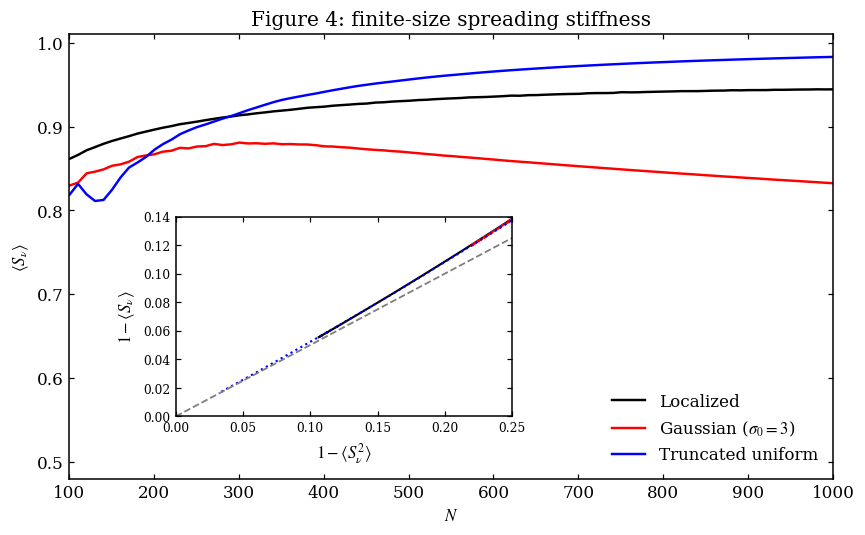

In [23]:
N_arr = fig4_data["N_arr"]
S_loc_m1, S_loc_m2 = fig4_data["S_loc_m1"], fig4_data["S_loc_m2"]
S_gauss_m1, S_gauss_m2 = fig4_data["S_gauss_m1"], fig4_data["S_gauss_m2"]
S_unif_m1, S_unif_m2 = fig4_data["S_unif_m1"], fig4_data["S_unif_m2"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(N_arr, S_loc_m1, color="black", lw=1.6, label="Localized")
ax.plot(N_arr, S_gauss_m1, color="red", lw=1.6, label=r"Gaussian ($\sigma_0=3$)")
ax.plot(N_arr, S_unif_m1, color="blue", lw=1.6, label="Truncated uniform")
ax.set(
    xlim=(100, 1000),
    ylim=(0.48, 1.01),
    xlabel="$N$",
    ylabel=r"$\langle S_\nu\rangle$",
    title="Figure 4: finite-size spreading stiffness",
)
ax.legend(frameon=False, loc="lower right")

ins = ax.inset_axes([0.14, 0.14, 0.44, 0.45])
ins.plot(1 - S_loc_m2, 1 - S_loc_m1, color="black", lw=1.4)
ins.plot(1 - S_gauss_m2, 1 - S_gauss_m1, color="red", lw=1.4, ls="--")
ins.plot(1 - S_unif_m2, 1 - S_unif_m1, color="blue", lw=1.4, ls=":")
x_ref = np.linspace(0, 0.25, 100)
ins.plot(
    x_ref, 0.5 * x_ref, color="gray", ls="--", lw=1.2, label="High-stiffness reference"
)
ins.set(
    xlim=(0, 0.25),
    ylim=(0, 0.14),
    xlabel=r"$1-\langle S_\nu^2\rangle$",
    ylabel=r"$1-\langle S_\nu\rangle$",
)
ins.tick_params(labelsize=8)
fig.tight_layout()
plt.show()

In [24]:
# Numerical check of the exact identity reconstructed from the cached moments.
for name, m1, m2 in [
    ("Localized", S_loc_m1, S_loc_m2),
    ("Gaussian", S_gauss_m1, S_gauss_m2),
    ("Truncated uniform", S_unif_m1, S_unif_m2),
]:
    lhs = 1 - m2
    rhs = 2 * (1 - m1) - (1 - 2 * m1 + m2)
    print(f"{name:18s}: maximum |lhs-rhs| = {np.max(np.abs(lhs-rhs)):.3e}")

# A few representative lattice sizes make the different trends easy to compare.
for N_query in [101, 501, 1001]:
    idx = np.where(N_arr == N_query)[0][0]
    print(
        f"N={N_query}: <S> = ({S_loc_m1[idx]:.4f}, {S_gauss_m1[idx]:.4f}, {S_unif_m1[idx]:.4f})"
    )

Localized         : maximum |lhs-rhs| = 0.000e+00
Gaussian          : maximum |lhs-rhs| = 0.000e+00
Truncated uniform : maximum |lhs-rhs| = 0.000e+00
N=101: <S> = (0.8616, 0.8298, 0.8188)
N=501: <S> = (0.9309, 0.8692, 0.9563)
N=1001: <S> = (0.9445, 0.8324, 0.9833)


### About Figure 4

- The localized-state mean stiffness rises overall with `N`.
- The truncated-uniform mean stiffness also rises overall and approaches one at large `N`.
- The Gaussian curve has a broad maximum at intermediate sizes and then decreases. Its initial width is kept fixed while the boundaries move farther away as `N` grows.
- At small sizes, Gaussian and truncated-uniform mean stiffnesses are similar even though the two initial profiles differ strongly. Their trends separate as the confinement grows.

The inset is a consistency check on the first and second moments in the high-stiffness regime; it is not a separate scaling law.

## 8. Normalized Kullback–Leibler divergence

The stiffness is based on temporal changes in the width. The paper introduces a second diagnostic to measure how far the spatial probability profile is from uniformity.

For a normalized distribution over `M` accessible sites, the entropy is

$$
H[P]= -\sum_jP(j)\ln P(j),
\tag{18}
$$

and its normalized divergence from the uniform distribution is

$$
D_{KL}=1-\frac{H[P]}{\ln M}.
\tag{19}
$$

Thus `DKL=0` for a uniform distribution over the chosen reference region, and larger values indicate greater spatial nonuniformity.

**The reference region matters.** The two auxiliary reflecting sites are excluded; probabilities on the `N` physical bulk sites are renormalized before computing the divergence.

### Parity correction for the localized state

A localized walk occupies only one position-parity sublattice at each time step. Comparing that instantaneous distribution to a uniform distribution over all `N` sites would count kinematically inaccessible sites as empty and overstate nonuniformity. The paper therefore combines two consecutive time steps:

$$
P^{(2)}(j,t)=\frac{M(t-1)P(j,t-1)+M(t)P(j,t)}{M(t-1)+M(t)},
\tag{20}
$$

where `M(t)` counts accessible sites at time `t`. The combined accessible region is the union of the two parity sectors, and its size is `M₂(t)=M(t−1)+M(t)`. The localized-state divergence is `DKL(t)=1−H[P^(2)]/ln M₂(t)`.

For the Gaussian and truncated-uniform initial conditions, both parity sectors are populated from the start, so the paper compares the instantaneous, bulk-renormalized probability directly with the uniform distribution over `N` sites.

In [25]:
def normalized_kl_to_uniform(probability):
    """Normalized KL divergence to a uniform law on the supplied support.

    Entries of zero probability are allowed. The vector is normalized inside
    this function, and the support size is the number of entries supplied.
    """
    p = np.asarray(probability, dtype=float)
    if p.ndim != 1 or p.size < 2:
        return 0.0
    total = p.sum()
    if total <= 0:
        raise ValueError("Probability mass must be positive")
    p = p / total
    positive = p > 0
    entropy = -np.sum(p[positive] * np.log(p[positive]))
    return float(1 - entropy / np.log(p.size))


def parity_corrected_localized_kl(p_previous, p_current, j_bulk, t, a):
    """Two-step parity-corrected D_KL for a localized walk at time t >= 1.

    p_previous and p_current are the bulk probability vectors at t-1 and t,
    each normalized on the bulk. The returned entropy is evaluated only on
    the union of the two kinematically accessible parity sectors.
    """
    if t < 1:
        return 0.0
    j_bulk = np.asarray(j_bulk)
    p0 = np.asarray(p_previous, dtype=float)
    p1 = np.asarray(p_current, dtype=float)
    mask0 = (np.abs(j_bulk) <= min(t - 1, a)) & (
        (j_bulk.astype(int) % 2) == ((t - 1) % 2)
    )
    mask1 = (np.abs(j_bulk) <= min(t, a)) & ((j_bulk.astype(int) % 2) == (t % 2))
    M0, M1 = int(mask0.sum()), int(mask1.sum())
    mask = mask0 | mask1
    M2 = M0 + M1
    p_two = (M0 * p0 + M1 * p1) / M2
    p_support = p_two[mask]
    p_support = p_support / p_support.sum()
    return normalized_kl_to_uniform(p_support)


# For a uniform distribution on M accessible sites, D_KL must be zero.
print("Uniform law on 9 sites:", normalized_kl_to_uniform(np.ones(9)))
print(
    "Point mass on 9-site reference:",
    normalized_kl_to_uniform([1, 0, 0, 0, 0, 0, 0, 0, 0]),
)

# At t=1, the localized walk's two-step construction is uniform on {-1,0,+1}.
j_bulk_demo = np.arange(-5, 6)
p0_demo = np.zeros(11)
p0_demo[5] = 1
p1_demo = np.zeros(11)
p1_demo[4] = 0.5
p1_demo[6] = 0.5
print(
    "Localized parity-corrected D_KL at t=1:",
    parity_corrected_localized_kl(p0_demo, p1_demo, j_bulk_demo, 1, 5),
)

Uniform law on 9 sites: 0.0
Point mass on 9-site reference: 1.0
Localized parity-corrected D_KL at t=1: 2.220446049250313e-16


## 9. Figure 5 — spatial homogenization over time and system size

The supplied Figure 5 cache uses `N=1001` for the time series and discards `t≤10⁵` when calculating its long-time finite-size moments. This cutoff is longer than the stiffness cutoff (`2×10⁴`): the paper reports that width oscillations settle into their bounded regime earlier than the slower spatial reorganization measured by `DKL`.

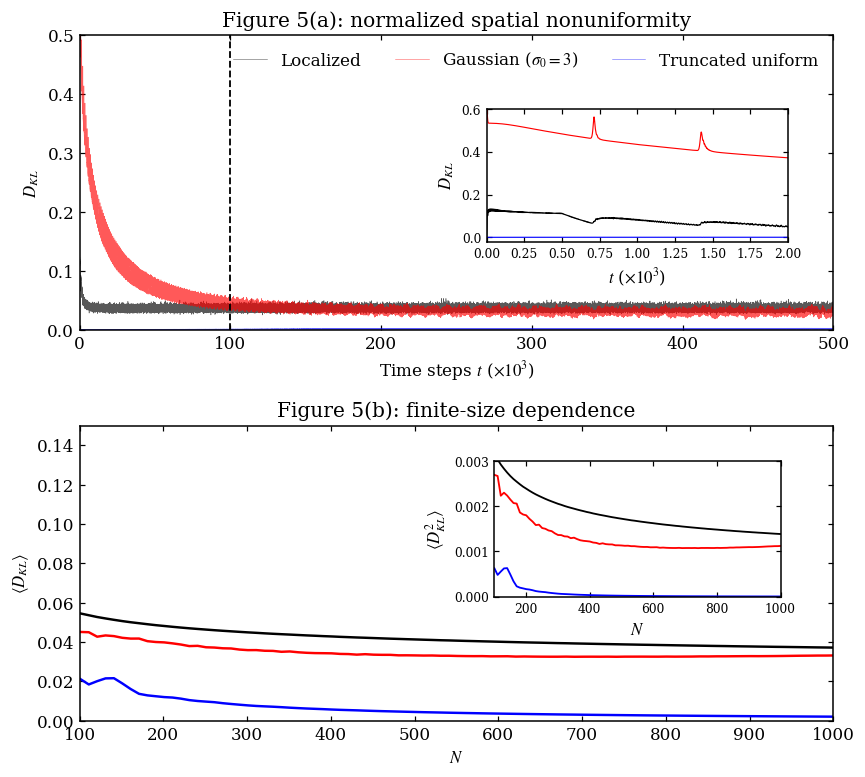

In [26]:
dkl_series = fig5_data["dkl_series"]
dkl_tc = int(fig5_data["tc"])
dkl_tmax = int(fig5_data["t_max"])
N_dkl = fig5_data["N_arr"]
mean_dkl = fig5_data["mean_dkl"]
mean_dkl2 = fig5_data["mean_dkl2"]

fig, (ax_time, ax_size) = plt.subplots(2, 1, figsize=(8, 7.2))
t_scaled = np.arange(dkl_tmax + 1) / 1000
for k, color in enumerate(["black", "red", "blue"]):
    ax_time.plot(
        t_scaled, dkl_series[k], color=color, lw=0.35, alpha=0.65, label=LABELS[k]
    )
ax_time.axvline(dkl_tc / 1000, color="black", ls="--", lw=1.2)
ax_time.set(
    xlim=(0, dkl_tmax / 1000),
    ylim=(0, 0.5),
    xlabel=r"Time steps $t$ ($\times10^3$)",
    ylabel=r"$D_{KL}$",
    title="Figure 5(a): normalized spatial nonuniformity",
)
ax_time.legend(frameon=False, ncol=3, loc="upper right")
ins_early = ax_time.inset_axes([0.54, 0.30, 0.40, 0.45])
for k, color in enumerate(["black", "red", "blue"]):
    ins_early.plot(np.arange(2001) / 1000, dkl_series[k, :2001], color=color, lw=0.75)
ins_early.set(
    xlim=(0, 2), ylim=(-0.02, 0.6), xlabel=r"$t$ ($\times10^3$)", ylabel=r"$D_{KL}$"
)
ins_early.tick_params(labelsize=8)

for k, color in enumerate(["black", "red", "blue"]):
    ax_size.plot(N_dkl, mean_dkl[k], color=color, lw=1.6, label=LABELS[k])
ax_size.set(
    xlim=(100, 1000),
    ylim=(0, 0.15),
    xlabel="$N$",
    ylabel=r"$\langle D_{KL}\rangle$",
    title="Figure 5(b): finite-size dependence",
)
ins_m2 = ax_size.inset_axes([0.55, 0.42, 0.38, 0.46])
for k, color in enumerate(["black", "red", "blue"]):
    ins_m2.plot(N_dkl, mean_dkl2[k], color=color, lw=1.2)
ins_m2.set(
    xlim=(100, 1000), ylim=(0, 0.003), xlabel="$N$", ylabel=r"$\langle D_{KL}^2\rangle$"
)
ins_m2.tick_params(labelsize=8)
fig.tight_layout()
plt.show()

### About Figure 5 — why stiffness and homogenization are different

- `DKL(t)` for the localized and Gaussian states decreases over a much longer time window than the transient width oscillations. The paper therefore uses `t_c=10⁵` for its long-time KL averages.
- The truncated-uniform initial state begins close to the uniform spatial reference, so its `DKL` remains small even though its instantaneous distribution continues to evolve.
- As `N` increases, the localized and Gaussian mean divergences are comparable and decrease; the truncated-uniform mean divergence is markedly smaller and approaches zero more rapidly.

This is the key conceptual comparison: a state can have a width that changes very little while its detailed spatial probability profile remains nonuniform, or it can remain close to spatially uniform while still undergoing coherent rearrangements. Width stiffness and spatial homogenization are complementary diagnostics, not interchangeable ones.


# 6. Conclusion

This study investigated the dynamics of discrete-time quantum walks confined to a finite one-dimensional lattice, focusing on how unitary reflecting boundaries influence spreading, temporal fluctuations, and spatial probability distributions.

The results show that confinement does not lead to a stationary probability distribution. Instead, repeated reflections and quantum interference produce persistent oscillations in the spatial width, even at long times. This behavior highlights an important distinction between classical diffusion, which approaches a uniform stationary distribution, and coherent quantum dynamics.

The spreading stiffness, $S_\nu(t)$, provides a dimensionless measure of the resistance of the spatial width to temporal variations. Its long-time behavior reveals a strong dependence on the initial spatial state:

- **Localized state:** the mean stiffness generally increases with the confinement size, approaching a high-stiffness regime.
- **Gaussian state:** the mean stiffness exhibits a nonmonotonic dependence, reaching a broad maximum at intermediate system sizes.
- **Truncated-uniform state:** the mean stiffness generally increases with system size, indicating progressively weaker width fluctuations.

The relationship between the first and second stiffness moments also approaches the expected high-stiffness consistency relation:

$$
1-\langle S_\nu\rangle
\simeq
\frac{1}{2}\left(1-\langle S_\nu^2\rangle\right).
\tag{21}
$$

The normalized Kullback–Leibler divergence, $D_{KL}$, provides a complementary perspective by quantifying spatial nonuniformity rather than temporal variations in the width. Its evolution reveals a slower spatial reorganization than that observed in the stiffness dynamics. In particular, the truncated-uniform initial state remains closer to the uniform reference distribution, while the localized and Gaussian states exhibit larger deviations.

These findings demonstrate that **dynamical stiffness and spatial homogenization are distinct properties of confined quantum walks**. A probability distribution may exhibit relatively small width fluctuations without necessarily becoming spatially uniform.

Overall, this work shows that the long-time behavior of confined quantum walks emerges from the interplay between boundary reflections, system size, quantum interference, and the initial spatial profile. The combination of spreading stiffness and Kullback–Leibler divergence therefore provides a useful framework for understanding different aspects of coherent transport under unitary confinement.
